# Nomogram

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

A graphical calculator for a regression model. Each predictor has its own scale; you read off points for a patient's values, add them up, and convert the total to a predicted probability on the bottom scale. It makes a model usable at the bedside without software.

## When to use

- Turn a logistic or Cox model into a tool clinicians can use by hand
- Show the relative weight each predictor carries in the model (length of each scale)
- Publish a prognostic model alongside its coefficients

## Avoid when

- The model has many interactions or non-linear terms that make the scales confusing
- An online calculator or EHR integration is available (it is less error-prone)
- The model is not validated (a nomogram makes an unvalidated model look authoritative)

## Alternatives

- Online risk calculator
- Forest plot of coefficients (to explain the model, not to use it)
- Points-based risk score table

## Design tips

- Scale the predictor with the largest effect range to 0–100 points
- Walk through one example patient on the chart so readers learn how to use it
- State the model's validation performance (C-index and calibration) in the caption

## Example

A logistic model for 5-year recurrence fitted on 1,500 synthetic patients using age, tumour size, number of positive lymph nodes and histological grade. An example patient is traced in orange.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.linear_model import LogisticRegression

### Data

In [2]:
rng = np.random.default_rng(17)
n = 1500
df = pd.DataFrame({
    "age": rng.uniform(35, 85, n).round(),
    "size_cm": rng.gamma(2.2, 1.0, n).clip(0.3, 7).round(1),
    "nodes": rng.poisson(1.6, n).clip(0, 12),
    "grade": rng.choice([1, 2, 3], n, p=[0.25, 0.45, 0.30]),
})
lin = -4.2 + 0.012 * df["age"] + 0.35 * df["size_cm"] + 0.30 * df["nodes"] + 0.55 * df["grade"]
df["recurrence"] = (rng.random(n) < 1 / (1 + np.exp(-lin))).astype(int)
model = LogisticRegression(C=1e6, max_iter=2000).fit(df[["age", "size_cm", "nodes", "grade"]], df["recurrence"])
coef = dict(zip(["age", "size_cm", "nodes", "grade"], model.coef_[0]))
print({k: round(v, 3) for k, v in coef.items()}, "intercept", round(model.intercept_[0], 2))

{'age': np.float64(0.014), 'size_cm': np.float64(0.319), 'nodes': np.float64(0.317), 'grade': np.float64(0.447)} intercept -4.02


### Plot

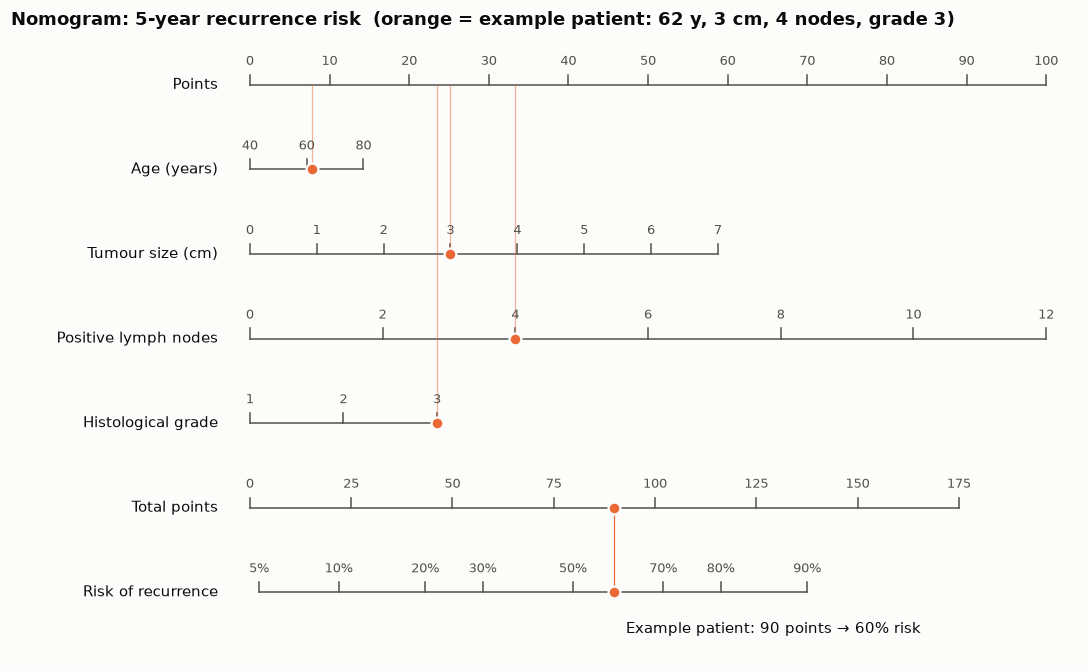

In [3]:
predictors = [  # (column, label, tick values)
    ("age", "Age (years)", np.arange(40, 81, 20)),
    ("size_cm", "Tumour size (cm)", np.arange(0, 8, 1)),
    ("nodes", "Positive lymph nodes", np.arange(0, 13, 2)),
    ("grade", "Histological grade", np.array([1, 2, 3])),
]
lo = {c: (ticks.min() if coef[c] > 0 else ticks.max()) for c, _, ticks in predictors}
span = {c: abs(coef[c]) * (ticks.max() - ticks.min()) for c, _, ticks in predictors}
scale = 100 / max(span.values())                         # largest effect -> 100 points
points = lambda c, v: abs(coef[c] * (v - lo[c])) * scale
total_max = sum(points(c, t.max() if coef[c] > 0 else t.min()) for c, _, t in predictors)
base_lp = model.intercept_[0] + sum(coef[c] * lo[c] for c, _, _ in predictors)
prob_of_total = lambda T: 1 / (1 + np.exp(-(base_lp + T / scale)))

patient = {"age": 62, "size_cm": 3.0, "nodes": 4, "grade": 3}
pt_points = {c: points(c, patient[c]) for c in patient}
pt_total = sum(pt_points.values())

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.axis("off")
rows = len(predictors) + 3
y = lambda r: rows - r
def scale_row(r, label, positions, labels, minor=None):
    ax.plot([min(positions), max(positions)], [y(r), y(r)], color="#52514e", linewidth=1)
    for p, l in zip(positions, labels):
        ax.plot([p, p], [y(r), y(r) + 0.12], color="#52514e", linewidth=1)
        ax.text(p, y(r) + 0.2, l, ha="center", va="bottom", fontsize=8.5, color="#52514e")
    ax.text(-4, y(r), label, ha="right", va="center", fontsize=10, color="#0b0b0b")

scale_row(0, "Points", np.arange(0, 101, 10), [str(v) for v in range(0, 101, 10)])
for i, (c, label, ticks) in enumerate(predictors, start=1):
    scale_row(i, label, [points(c, v) for v in ticks], [f"{v:g}" for v in ticks])
    ax.scatter(pt_points[c], y(i), s=60, color=PALETTE[1], zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.plot([pt_points[c]] * 2, [y(i), y(0)], color=PALETTE[1], linewidth=0.8, alpha=0.5)
r_tot = len(predictors) + 1
to_x = lambda T: T / total_max * 100                     # total-points scale drawn across the full width
tot_ticks = np.arange(0, total_max + 1, 25)
scale_row(r_tot, "Total points", [to_x(t) for t in tot_ticks], [f"{t:g}" for t in tot_ticks])
probs = [p for p in [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]
         if prob_of_total(0) <= p <= prob_of_total(total_max)]
T_of = lambda p: (np.log(p / (1 - p)) - base_lp) * scale
scale_row(r_tot + 1, "Risk of recurrence", [to_x(T_of(p)) for p in probs], [f"{p:.0%}" for p in probs])
ax.scatter(to_x(pt_total), y(r_tot), s=60, color=PALETTE[1], zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(to_x(pt_total), y(r_tot + 1), s=60, color=PALETTE[1], zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.plot([to_x(pt_total)] * 2, [y(r_tot), y(r_tot + 1)], color=PALETTE[1], linewidth=0.8)
ax.text(to_x(pt_total) + 1.5, y(r_tot + 1) - 0.35,
        f"Example patient: {pt_total:.0f} points → {prob_of_total(pt_total):.0%} risk",
        fontsize=9.5, color="#0b0b0b", va="top")
ax.set_xlim(-30, 104)
ax.set_ylim(y(r_tot + 1) - 0.8, y(0) + 0.6)
ax.set_title("Nomogram: 5-year recurrence risk  (orange = example patient: 62 y, 3 cm, 4 nodes, grade 3)",
             loc="left", fontsize=11.5)
fig.tight_layout()
plt.show()

## How to read it

The example patient (orange dots) scores points on each predictor scale. The points add up to the total marked on the "Total points" scale, which lines up with their predicted recurrence risk below it. The longest scale (lymph nodes) is the strongest predictor.

---
Standalone script: [`nomogram.py`](nomogram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)